# PDAN Part 3
*James Hart*



Dataset:


In [2]:
# %pip install pandas==2.3.3
# %pip install nltk
# %pip install pyspark
# %pip install numpy
# %pip install scikit-learn
# %pip install tensorflow
# %pip install nbformat
# %pip install plotly
# %pip install PyArrow
# %pip install ElementTree
# %pip install seaborn
# %pip install xgboost

### Spark Setup

The data loading, inspection, cleaning, exploratory summaries, and feature preparation below use PySpark DataFrames.
Only small aggregated result sets are collected to the driver for visualisation; the source dataset is not converted to pandas.


To setup Spark through PySpark certain requirements have to be met, the correct versioning of Python, PySpark, Java and tensorflow packages. With Spark being very specific about which versions are to be installed to work correctly. 

Specific versions I am running:
- Python 3.13.5
- Java 25.0.4
- Pandas 2.3.3

Due to the lack of native gpu support in tensorflow on windows, everything was run using my Ryzen 5 3600 cpu (10years old), this impacted performance quite heavily, therefore certain cells and parameters have been tuned to optimse the overall performance and speed.

In [3]:
# Configure the Python executables used by PySpark.
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable


In [4]:
# Make sure Pyspark works correctly without erroring out in the background
import os
import sys
import importlib.metadata

# version of pandas that runs with Java 25.0.4 and Python 3.13.5
PANDAS_REQUIRED_VERSION = "2.3.3"

try:
    installed_version = importlib.metadata.version("pandas")
    if installed_version != PANDAS_REQUIRED_VERSION:
        raise ImportError(f"Version mismatch: Found {installed_version}")
except importlib.metadata.PackageNotFoundError:
    print(f"Error: pandas is not installed.")
    sys.exit(1)
except ImportError as e:
    print(f"{e}. Run: pip install --upgrade pandas=={PANDAS_REQUIRED_VERSION}")
    sys.exit(1)

import pandas as pd
print(f"Loaded pandas: {pd.__version__}")

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
print()

Loaded pandas: 2.3.3



In [ ]:
# Create a PySpark session with additional memory.
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("PDAN8412 Part 3")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "10g")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.driver.maxResultSize", "2g")
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)


## Import Dataset

Extract labels from XML sidecar files without making Spark enumerate thousands of small files

In [ ]:
import csv
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from xml.etree import ElementTree

# directories of the xml sidecar files and the output CSV file
ANNOTATIONS_DIR = Path("dataset/Annotations")
LABELS_CSV = Path("dataset/annotation_labels.csv")

# Parse the XML annotation files and extract the filename and object labels
def parse_annotation(annotation_path):
    root = ElementTree.parse(annotation_path).getroot()
    filename = root.findtext("filename")
    labels = sorted({name.text for name in root.findall("./object/name") if name.text})
    if not filename or not labels:
        raise ValueError(f"Missing filename or object labels in {annotation_path}")
    return filename, "|".join(labels)

# Use a thread pool to parse the XML files concurrently and write the results to a CSV file
annotation_paths = sorted(ANNOTATIONS_DIR.glob("*.xml"))
if not annotation_paths:
    raise FileNotFoundError(f"No XML annotations found in {ANNOTATIONS_DIR}")

with ThreadPoolExecutor() as executor:
    annotation_rows = list(executor.map(parse_annotation, annotation_paths))

with LABELS_CSV.open("w", newline="", encoding="utf-8") as labels_file:
    writer = csv.writer(labels_file)
    writer.writerow(["filename", "label"])
    writer.writerows(annotation_rows)

print(f"Wrote {len(annotation_rows):,} annotation rows to {LABELS_CSV}")


# AI used to create a reference script to parse the XML files and write the results to a CSV file.
# Then simplified for my use case and improved using threads for performance due to 17,000+ XML files to parse.

Wrote 17,125 annotation rows to dataset\annotation_labels.csv


### Spark

In [7]:
from pathlib import Path
from pyspark.sql.functions import col, regexp_extract

# check if file already exists
if not os.path.exists("dataset/JPEGImages"):
    raise FileNotFoundError("Dataset directory not found")

# Enumerate files with Python to avoid Hadoop's broken Windows NativeIO directory listing.
image_paths = [str(path.resolve()) for path in Path("dataset/JPEGImages").glob("*.jpg")]
image_df = spark.read.format("binaryFile").load(image_paths)

# Extract filename from path as the join key
image_df = image_df.withColumn(
    "filename",
    regexp_extract(col("path"), r"([^/\\]+)\.jpg$", 1)
)

In [8]:
print("Images read:", image_df.count())
image_df.select("path", "length").show(5, truncate=False)

Images read: 17125
+---------------------------------------------------------------------------------------------------------+------+
|path                                                                                                     |length|
+---------------------------------------------------------------------------------------------------------+------+
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_004537.jpg|855251|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2011_006230.jpg|782249|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_001444.jpg|677151|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_004444.jpg|373871|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2012_003706.jpg|333836|
+------------------------------------------------------------

In [9]:
# Load annotation labels and extract the image stem to match image_df.filename.
annotation_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(LABELS_CSV))
    .withColumn(
        "filename",
        regexp_extract(col("filename"), r"([^/\\]+)\.jpg$", 1)
    )
)

# Join image metadata with annotation labels.
image_annotation_df = image_df.join(
    annotation_df,
    on="filename",
    how="inner"
)

print("Joined images:", image_annotation_df.count())
image_annotation_df.select("filename", "label", "length").show(10, truncate=False)

Joined images: 17125
+-----------+------------------------------------+------+
|filename   |label                               |length|
+-----------+------------------------------------+------+
|2009_004537|bottle|chair|diningtable|pottedplant|855251|
|2011_006230|person                              |782249|
|2009_001444|cat                                 |677151|
|2009_004444|bicycle                             |373871|
|2012_003706|person                              |333836|
|2009_002194|bicycle                             |320867|
|2009_003218|cow                                 |304426|
|2008_002866|horse|person                        |300506|
|2012_004075|person                              |294114|
|2008_000647|person                              |291640|
+-----------+------------------------------------+------+
only showing top 10 rows


## EDA


In [10]:
from pyspark.sql import functions as F

summary_df = image_annotation_df.agg(
    F.countDistinct("filename").alias("images"),
    F.count("label").alias("annotation_rows"),
    F.min("length").alias("smallest_bytes"),
    F.max("length").alias("largest_bytes"),
    F.round(F.avg("length"), 0).alias("average_bytes"),
)
summary_df.show(truncate=False)

+------+---------------+--------------+-------------+-------------+
|images|annotation_rows|smallest_bytes|largest_bytes|average_bytes|
+------+---------------+--------------+-------------+-------------+
|17125 |17125          |7319          |855251       |112235.0     |
+------+---------------+--------------+-------------+-------------+



In [11]:
label_counts_df = (
    image_annotation_df
    .select(F.explode(F.split("label", "\\|"))
            .alias("label"))
    .groupBy("label")
    .count()
    .orderBy(F.desc("count"))
)

label_counts_df.show(20, truncate=False)

+-----------+-----+
|label      |count|
+-----------+-----+
|person     |9583 |
|chair      |1366 |
|dog        |1341 |
|car        |1284 |
|cat        |1128 |
|bottle     |812  |
|bird       |811  |
|sofa       |742  |
|aeroplane  |716  |
|diningtable|691  |
|tvmonitor  |645  |
|pottedplant|613  |
|bicycle    |603  |
|train      |589  |
|motorbike  |575  |
|boat       |549  |
|horse      |526  |
|bus        |467  |
|sheep      |357  |
|cow        |340  |
+-----------+-----+



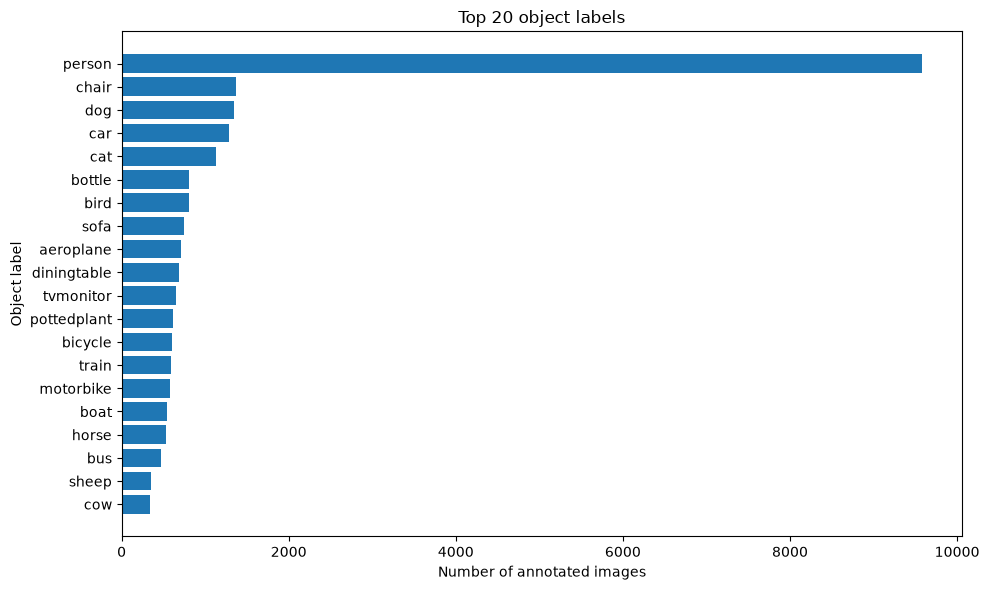

In [12]:
import matplotlib.pyplot as plt

top_labels = label_counts_df.limit(20).toPandas()
plt.figure(figsize=(10, 6))
plt.barh(top_labels["label"][::-1], top_labels["count"][::-1])
plt.xlabel("Number of annotated images")
plt.ylabel("Object label")
plt.title("Top 20 object labels")
plt.tight_layout()
plt.show()

In [13]:
quality_df = image_annotation_df.select(
    F.sum(F.col("label").isNull().cast("int")).alias("missing_labels"),
    F.sum((F.col("length") <= 0).cast("int")).alias("non_positive_file_sizes"),
)
quality_df.show()

+--------------+-----------------------+
|missing_labels|non_positive_file_sizes|
+--------------+-----------------------+
|             0|                      0|
+--------------+-----------------------+



In [14]:
from PIL import Image

sample_size = 120

# Randomly select images 
sampled_filenames = [
    row["filename"]
    for row in (
        image_annotation_df
        .select("filename")
        .distinct()
        .orderBy(F.rand())
        .limit(sample_size)
        .collect()
    )
]

image_path_by_filename = {
    Path(path).stem: path
    for path in image_paths
}

image_properties = []

for filename in sampled_filenames:
    image_path = image_path_by_filename.get(filename)

    if image_path is None:
        continue

    with Image.open(image_path) as image:
        image_properties.append({
            "filename": filename,
            "width": image.width,
            "height": image.height,
            "channels": len(image.getbands()),
            "mode": image.mode,
        })

image_properties_df = pd.DataFrame(image_properties)
display(image_properties_df)

,filename,width,height,channels,mode
0,2010_003119,500,317,3,RGB
1,2008_002129,500,333,3,RGB
2,2011_003358,500,343,3,RGB
3,2008_006002,500,375,3,RGB
4,2011_006934,500,333,3,RGB
...,...,...,...,...,...
115,2008_005902,375,500,3,RGB
116,2009_004919,500,375,3,RGB
117,2011_000872,500,336,3,RGB
118,2008_002243,375,500,3,RGB


In [15]:
# stats of subset
image_properties_df.describe()

,width,height,channels
count,120.000000,120.000000,120.0
mean,476.650000,383.000000,3.0
std,51.835657,59.639252,0.0
min,333.000000,263.000000,3.0
25%,500.000000,337.500000,3.0
50%,500.000000,375.000000,3.0
75%,500.000000,375.000000,3.0
max,500.000000,500.000000,3.0


## Human classification CNN

converts them to a binary target: an image is positive when its annotation includes person.


In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

labels_df = pd.read_csv(LABELS_CSV)
labels_df["path"] = labels_df["filename"].map(
    {Path(path).name: path for path in image_paths}
)
labels_df = labels_df.dropna(subset=["path"]).copy()
labels_df["human"] = labels_df["label"].str.split("|").apply(
    lambda labels: int("person" in labels)
)
labels_df = labels_df[["path", "human"]].drop_duplicates("path")

train_df, temp_df = train_test_split(
    labels_df, test_size=0.30, random_state=SEED, stratify=labels_df["human"]
)
validation_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["human"]
)
print({name: len(frame) for name, frame in {
    "train": train_df, "validation": validation_df, "test": test_df
}.items()})
print(labels_df["human"].value_counts(normalize=True).sort_index())


{'train': 11987, 'validation': 2569, 'test': 2569}
human
0    0.440409
1    0.559591
Name: proportion, dtype: float64


Images are decoded as RGB, resized to a common shape, and augmented only during training.


In [17]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, tf.cast(label, tf.float32)


def make_dataset(frame, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame["path"].to_numpy(), frame["human"].to_numpy())
    )
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED)
    return dataset.map(load_image, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, shuffle=True)
validation_ds = make_dataset(validation_df)
test_ds = make_dataset(test_df)


## Baseline Model

A small CNN learns image features and outputs the probability that a person is present.


In [34]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.Rescaling(1 / 255.0),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

counts = train_df["human"].value_counts()
class_weight = (len(train_df) / (2 * counts)).to_dict()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

baseline_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=2, restore_best_weights=True
    )],
)

Epoch 1/30


c:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - accuracy: 0.5644 - auc: 0.5874 - loss: 0.6827 - val_accuracy: 0.6209 - val_auc: 0.6411 - val_loss: 0.6603
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.5881 - auc: 0.6225 - loss: 0.6719 - val_accuracy: 0.6049 - val_auc: 0.6572 - val_loss: 0.6644
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5990 - auc: 0.6369 - loss: 0.6669 - val_accuracy: 0.6135 - val_auc: 0.6625 - val_loss: 0.6570
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.6046 - auc: 0.6450 - loss: 0.6640 - val_accuracy: 0.6438 - val_auc: 0.6778 - val_loss: 0.6448
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.6079 - auc: 0.6509 - loss: 0.6615 - val_accuracy: 0.6512 - val_auc: 0.6836 - val_loss: 0.6455
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.6082 - auc: 0.6545 - loss: 0.6599 - val_accuracy: 0.6559 - val_auc: 0.6877 - val_loss: 0.6418
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
# model_dir = Path("models")
# model_dir.mkdir(exist_ok=True)

# model_path = model_dir / "human_classifier.keras"
# model.save(model_path)

# print(f"Model saved to: {model_path.resolve()}")

Model saved to: C:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\models\human_classifier.keras


### Evaluation

final accuracy, AUC, precision, recall, and the confusion matrix.


Test loss: 0.631
Test accuracy: 0.654
Test AUC: 0.694
              precision    recall  f1-score   support

   no person       0.63      0.53      0.58      1132
      person       0.67      0.75      0.71      1437

    accuracy                           0.65      2569
   macro avg       0.65      0.64      0.64      2569
weighted avg       0.65      0.65      0.65      2569



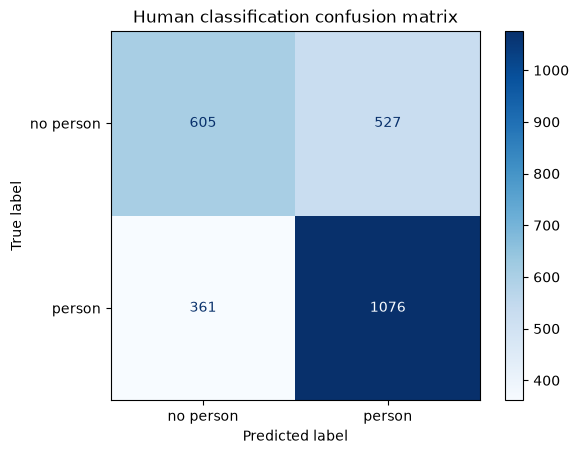

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_loss, test_accuracy, test_auc = model.evaluate(test_ds, verbose=0)
test_probabilities = model.predict(test_ds, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels = test_df["human"].to_numpy()

print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test AUC: {test_auc:.3f}")
print(classification_report(
    test_labels, test_predictions, target_names=["no person", "person"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(test_labels, test_predictions),
    display_labels=["no person", "person"],
).plot(cmap="Blues")
plt.title("Human classification confusion matrix")
plt.show()


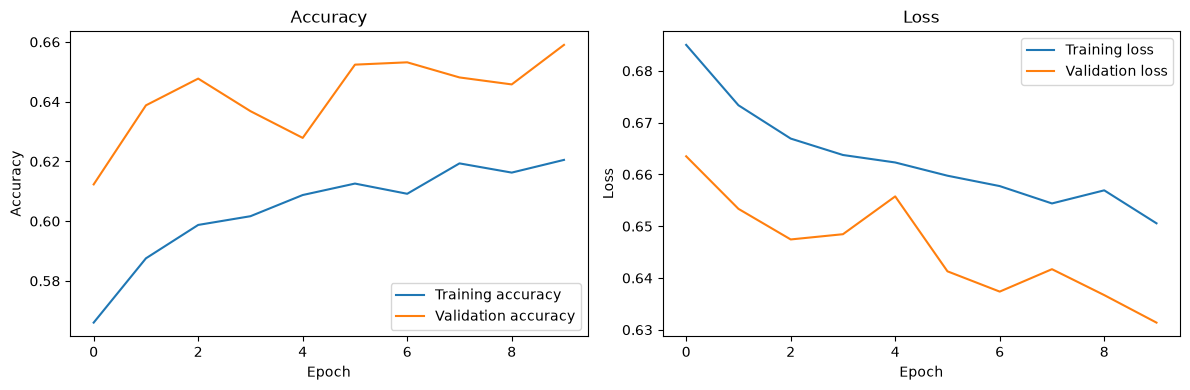

In [20]:
# training and validation accuracy and loss
training_history = baseline_history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(training_history["accuracy"], label="Training accuracy")
axes[0].plot(training_history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(training_history["loss"], label="Training loss")
axes[1].plot(training_history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Improved Model

In [23]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),   # cheap, keep
    tf.keras.layers.Rescaling(1/255.0),

    tf.keras.layers.Conv2D(24, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),             

    tf.keras.layers.Conv2D(48, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(48, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(96, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(96, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(96, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

counts = train_df["human"].value_counts()
class_weight = (len(train_df) / (2 * counts)).to_dict()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc"),
             tf.keras.metrics.Precision(), tf.keras.metrics.Recall()],
)

improved_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=[
    tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True,
                                     monitor="val_auc", mode="max"),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                         monitor="val_loss", min_lr=1e-6),
        ],
)

Epoch 1/30


c:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 108s 283ms/step - accuracy: 0.6120 - auc: 0.6554 - loss: 0.6586 - precision_1: 0.6652 - recall_1: 0.6173 - val_accuracy: 0.6403 - val_auc: 0.6869 - val_loss: 0.6389 - val_precision_1: 0.6785 - val_recall_1: 0.6794 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 102s 272ms/step - accuracy: 0.6581 - auc: 0.7106 - loss: 0.6259 - precision_1: 0.7096 - recall_1: 0.6586 - val_accuracy: 0.5115 - val_auc: 0.7396 - val_loss: 0.7801 - val_precision_1: 0.8453 - val_recall_1: 0.1558 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 101s 269ms/step - accuracy: 0.6776 - auc: 0.7332 - loss: 0.6088 - precision_1: 0.7247 - recall_1: 0.6834 - val_accuracy: 0.6454 - val_auc: 0.7115 - val_loss: 0.6259 - val_precision_1: 0.6338 - val_recall_1: 0.8679 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 104s 278ms/step - accuracy: 0.6902 - auc: 0.7481 - loss: 0.5959 - precision_1: 0.7389 - recall_1: 0.6905 - val_accuracy: 0.6532 - val_auc

In [ ]:
# model_dir = Path("models")
# model_dir.mkdir(exist_ok=True)

# model_path = model_dir / "human_classifier_improved.keras"
# model.save(model_path)

# print(f"Model saved to: {model_path.resolve()}")

Model saved to: C:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\models\human_classifier_improved.keras


### Evaluation

Test loss: 0.378
Test accuracy: 0.827
Test AUC: 0.910
              precision    recall  f1-score   support

   no person       0.77      0.87      0.82      1132
      person       0.89      0.79      0.84      1437

    accuracy                           0.83      2569
   macro avg       0.83      0.83      0.83      2569
weighted avg       0.83      0.83      0.83      2569



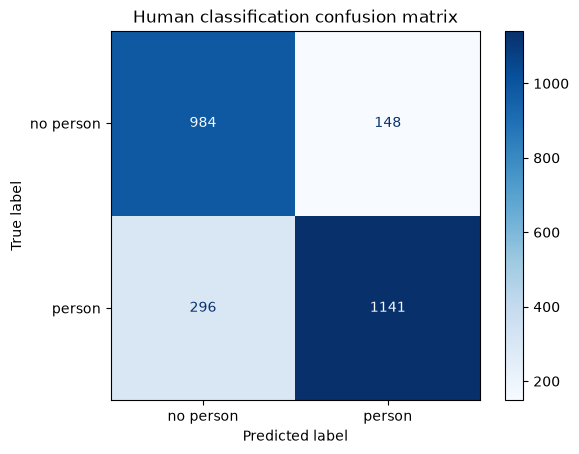

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

improved_evaluation = model.evaluate(test_ds, verbose=0, return_dict=True)

test_loss = improved_evaluation["loss"]
test_accuracy = improved_evaluation["accuracy"]
test_auc = improved_evaluation["auc"]
test_probabilities = model.predict(test_ds, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels = test_df["human"].to_numpy()

print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test AUC: {test_auc:.3f}")
print(classification_report(
    test_labels, test_predictions, target_names=["no person", "person"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(test_labels, test_predictions),
    display_labels=["no person", "person"],
).plot(cmap="Blues")
plt.title("Human classification confusion matrix")
plt.show()



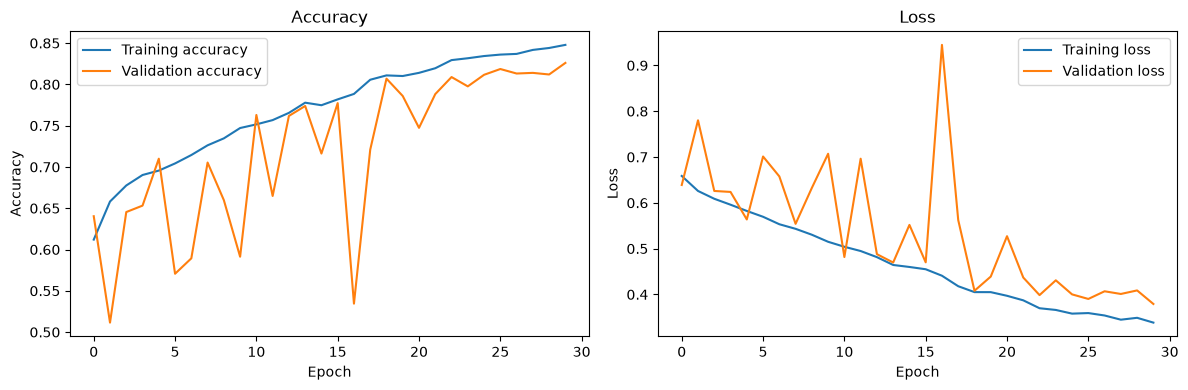

In [25]:
# training and validation accuracy and loss
training_history = history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(training_history["accuracy"], label="Training accuracy")
axes[0].plot(training_history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(training_history["loss"], label="Training loss")
axes[1].plot(training_history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Comparison

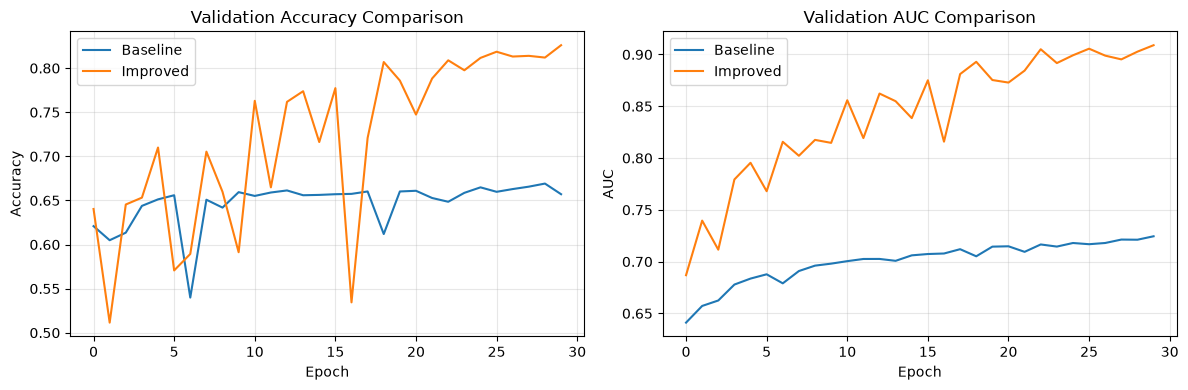

In [35]:
# comparison of baseline and improved training 

baseline_metrics = baseline_history.history
improved_metrics = (
    improved_history.history
    if hasattr(improved_history, "history")
    else improved_history
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for metrics, name in [
    (baseline_metrics, "Baseline"),
    (improved_metrics, "Improved"),
]:
    axes[0].plot(metrics["val_accuracy"], label=name)
    axes[1].plot(metrics["val_auc"], label=name)

axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation AUC Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()